# Figure 4, Panel D

Barplots showing expression (log2(TPM+1)) of canonical IFNg- and Dex-induced genes at 1h and 6h with stimulus alone or after 0.5h pretreatment with BAFinh (10µM). Expression values for individual replicates indicated by points. P-values comparing Stimulus expression to BAFinh -> Stimulus are from one-sided Student's t-tests.

*Outputs: paneld_ifny.pdf, paneld_dex.pdf*

# Setup

In [3]:
# load packages
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(here)
here::i_am("figures/Figure4/Panel_D/PanelD_example_genes.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         patchwork_1.3.0    RColorBrewer_1.1-3 lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# Plotting function

# Read data

In [4]:
# TPMs
tpms <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "VST_abundance_batchCorr.tsv"
  ),
  sep = "\t"
)
# gene-level metadata
row.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "gene_metadata.tsv"
  ),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "rsem_metadata.tsv"
  ),
  sep = "\t"
)


# Generate plots

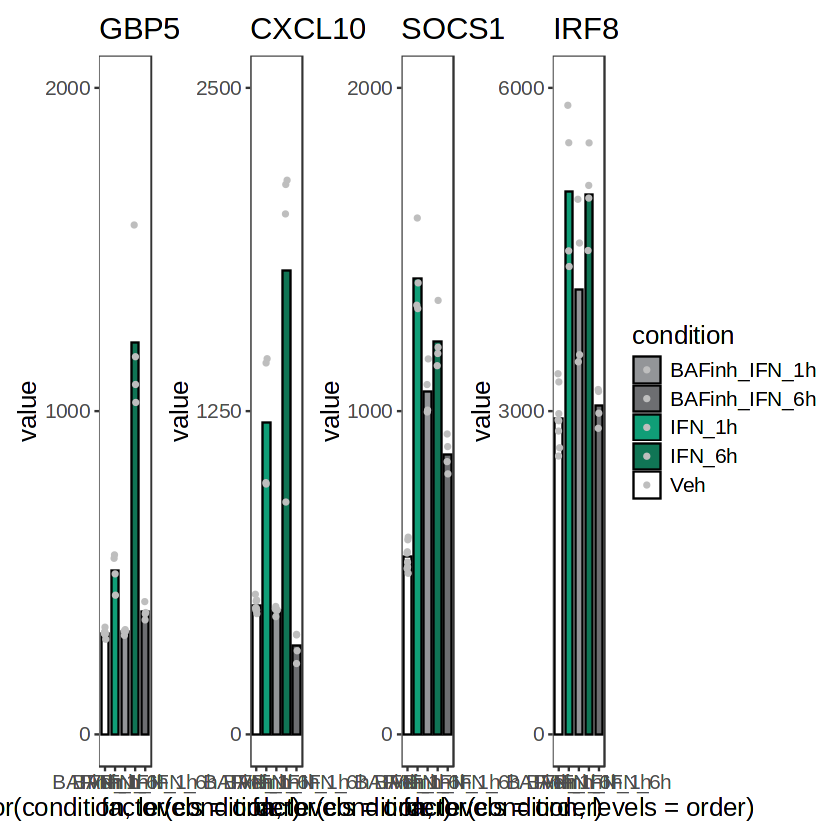

In [122]:
order <- c("Veh", "IFN_1h", "BAFinh_IFN_1h", "IFN_6h", "BAFinh_IFN_6h")
ifn_cols <- c("Veh"="white", 
              "IFN_1h"="#109e77", 
              "BAFinh_IFN_1h"="#939598",
              "IFN_6h"= "#107555",
              "BAFinh_IFN_6h"="#6d6e71")

plot_tpms <- function(tpms, rowdata, gene, conditions){
    temp <- tpms %>% data.frame() %>% mutate(gene_name=rowdata$gene_name) #add gene name from row metadata
    temp <- temp %>% filter(gene_name == gene) #filter to only include gene of interest
    temp <- temp %>% 
                pivot_longer(!gene_name) %>% #make into tidy format
                mutate(condition = gsub("_r.*$", "", name), #extract condition (dose + time) as well as dose and time separately
                    time=gsub("^.*_", "", condition), 
                    treatment=gsub("_.h$", "", condition)) %>% 
                filter(treatment %in% conditions) 
    temp <- temp %>% mutate(condition=case_when(grepl("Veh", condition) ~ "Veh", TRUE ~ condition), #combine vehicle treated samples into one category
                            time=case_when(grepl("Veh", condition) ~ "0h", TRUE ~ time),
                           value=2^value) #log2 transform TPMs for plotting
    #plot results
    plot <- ggplot(temp, aes(x=factor(condition, levels=order),y=value, fill=condition)) + 
        stat_summary(fun=mean, geom="col", width=.75, color="black", position=position_dodge()) +  #mean TPM as column
        geom_point(position=position_jitter(height=0,width=.1),  size=1, color="grey") + #individual replicates as points
        ggtitle(gene) +
        scale_fill_manual(values=ifn_cols)
    return(list(temp, plot))
}

IFNy_targets <- c("GBP5", "IRF8", "CXCL10","SOCS1")
#plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))
p1 <- plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN", "BAFinh_IFN"))[[2]] + coord_cartesian(ylim=c(0,2000)) + scale_y_continuous(breaks=c(0,1000,2000))
p2 <- plot_tpms(tpms, row.data, IFNy_targets[2], c("Veh", "IFN", "BAFinh_IFN"))[[2]] + coord_cartesian(ylim=c(0,6000)) + scale_y_continuous(breaks=c(0,3000,6000))
p3 <- plot_tpms(tpms, row.data, IFNy_targets[3], c("Veh", "IFN", "BAFinh_IFN"))[[2]] + coord_cartesian(ylim=c(0,2500)) + scale_y_continuous(breaks=c(0,1250,2500))
p4 <- plot_tpms(tpms, row.data, IFNy_targets[4], c("Veh", "IFN", "BAFinh_IFN"))[[2]] + coord_cartesian(ylim=c(0,2000)) + scale_y_continuous(breaks=c(0,1000,2000))

(p1 | p3 | p4 | p2) + plot_layout(guides="collect")
ggsave("panelD_ifny.pdf",width=11,height=3)

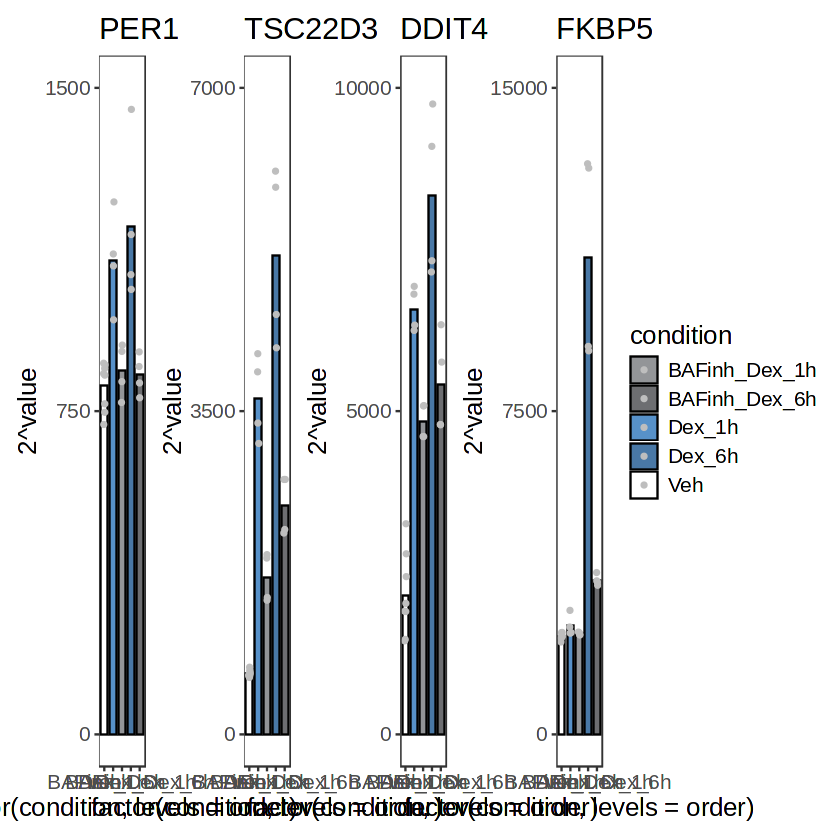

In [123]:
#Dex
order <- c("Veh", "Dex_1h", "BAFinh_Dex_1h", "Dex_6h", "BAFinh_Dex_6h")
dex_cols <- c("Veh"="white", 
              "Dex_1h"="#5791c9", 
              "BAFinh_Dex_1h"="#939598",
              "Dex_6h"= "#4978a6",
              "BAFinh_Dex_6h"="#6d6e71")

plot_tpms <- function(tpms, rowdata, gene, conditions){
    temp <- tpms %>% data.frame() %>% mutate(gene_name=rowdata$gene_name) #add gene name from row metadata
    temp <- temp %>% filter(gene_name == gene) #filter to only include gene of interest
    temp <- temp %>% 
                pivot_longer(!gene_name) %>% #make into tidy format
                mutate(condition = gsub("_r.*$", "", name), #extract condition (dose + time) as well as dose and time separately
                    time=gsub("^.*_", "", condition), 
                    treatment=gsub("_.h$", "", condition)) %>% 
                filter(treatment %in% conditions) 
    temp <- temp %>% mutate(condition=case_when(grepl("Veh", condition) ~ "Veh", TRUE ~ condition), #combine vehicle treated samples into one category
                            time=case_when(grepl("Veh", condition) ~ "0h", TRUE ~ time)) #log2 transform TPMs for plotting

    #plot results
    plot <- ggplot(temp, aes(x=factor(condition, levels=order),y=2^value, fill=condition)) + 
        stat_summary(fun=mean, geom="col", width=.75, color="black", position=position_dodge()) +  #mean TPM as column
        geom_point(position=position_jitter(height=0,width=.1),  size=1, color="grey") + #individual replicates as points
        ggtitle(gene) + 
        scale_fill_manual(values=dex_cols)
    return(list(temp, plot))
}

Dex_targets <- c("DDIT4", "PER1", "TSC22D3","FKBP5")
#plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))
p1 <- plot_tpms(tpms, row.data, Dex_targets[1], c("Veh", "Dex", "BAFinh_Dex"))[[2]] + coord_cartesian(ylim=c(0,10000)) + scale_y_continuous(breaks=c(0,5000,10000))
p2 <- plot_tpms(tpms, row.data, Dex_targets[2], c("Veh", "Dex", "BAFinh_Dex"))[[2]] + coord_cartesian(ylim=c(0,1500)) + scale_y_continuous(breaks=c(0,750,1500))
p3 <- plot_tpms(tpms, row.data, Dex_targets[3], c("Veh", "Dex", "BAFinh_Dex"))[[2]] + coord_cartesian(ylim=c(0,7000)) + scale_y_continuous(breaks=c(0,3500,7000))
p4 <- plot_tpms(tpms, row.data, Dex_targets[4], c("Veh", "Dex", "BAFinh_Dex"))[[2]] + coord_cartesian(ylim=c(0,15000)) + scale_y_continuous(breaks=c(0,7500,15000))

(p2 | p3 | p1 | p4) + plot_layout(guides="collect")
ggsave("panelD_dex.pdf",width=11,height=3)

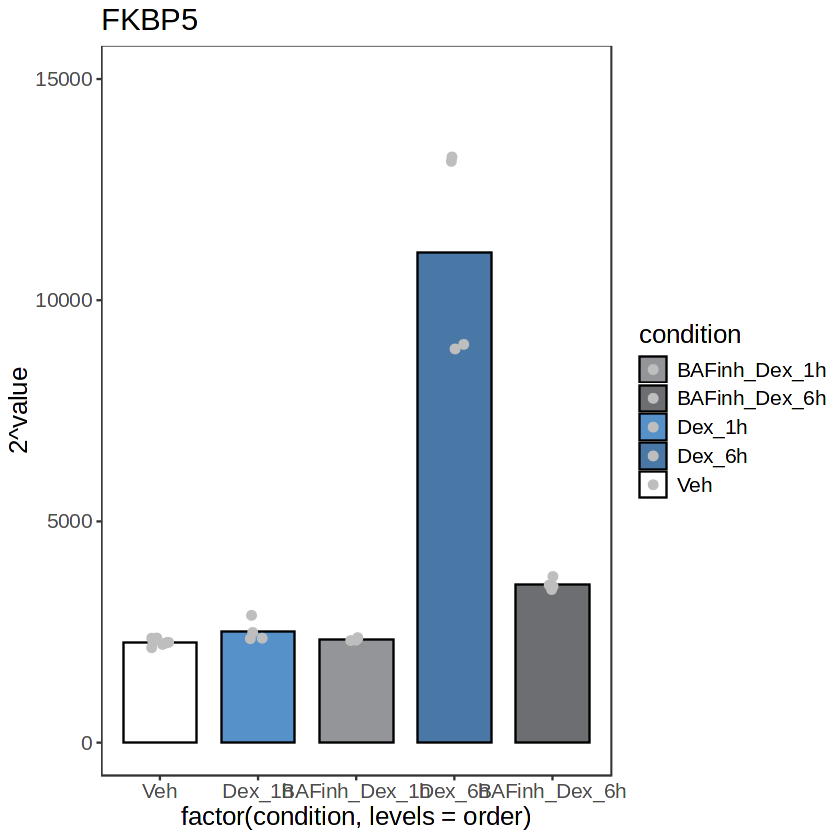

In [113]:
plot_tpms(tpms, row.data, Dex_targets[4], c("Veh", "Dex", "BAFinh_Dex"))[[2]] + coord_cartesian(ylim=c(0,15000))

# p-values with multiple testing correction

In [5]:
genes <- c("GBP5", "CXCL10", "SOCS1", "IRF8",
           "PER1", "TSC22D3", "DDIT4", "FKBP5")

pval_table <- tidyr::expand_grid(gene = genes, time = c(1, 6)) %>%
  mutate(
    stimulus = if_else(gene %in% genes[1:4], "IFN", "Dex"),
    p_raw = purrr::pmap_dbl(
      list(gene, time, stimulus),
      function(gene, time, stimulus) {
        i <- which(row.data$gene_name == gene)
        cols <- paste0(stimulus, "_", time, "h_r", 1:4)
        x <- (as.numeric(unlist(tpms[i, cols])))
        y <- (as.numeric(unlist(tpms[i, paste0("BAFinh_", cols)])))
        t.test(x, y, var.equal = TRUE)$p.value
      }
    )
  ) %>%
  group_by(stimulus) %>%
  mutate(padj = p.adjust(p_raw, method = "bonferroni"), sig=case_when(padj < 0.05 & padj > 0.01 ~ "*", 
                                                              padj < 0.01 & padj > 0.001 ~ "**", 
                                                              padj < 0.001 ~ "***", 
                                                              TRUE ~ "")) %>%
  ungroup()
pval_table
write.table(pval_table, "pval_table.tsv", row.names=F, sep='\t')

gene,time,stimulus,p_raw,padj,sig
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
GBP5,1,IFN,2.277448e-04,0.0018219585,**
GBP5,6,IFN,2.652013e-05,0.0002121610,***
CXCL10,1,IFN,2.329726e-04,0.0018637805,**
CXCL10,6,IFN,3.974634e-04,0.0031797071,**
SOCS1,1,IFN,2.610136e-03,0.0208810847,*
SOCS1,6,IFN,3.822902e-04,0.0030583218,**
IRF8,1,IFN,1.314487e-01,1.0000000000,
IRF8,6,IFN,6.331971e-05,0.0005065577,***
PER1,1,Dex,6.215428e-03,0.0497234222,*
